# 01 · EDA & Tiền xử lý — Building Energy Efficiency

**Đồ án môn Học máy (mã HP 608807) — Khoa CNTT, Trường ĐH Xây dựng Hà Nội**
**Nhóm 01** · Dữ liệu: *UCI Energy Efficiency Dataset* (768 mẫu, 8 đặc trưng, 2 biến mục tiêu)

---

## Mục tiêu của notebook này

1. Kiểm tra chất lượng dữ liệu: thiếu, trùng lặp, kiểu dữ liệu, miền giá trị.
2. EDA: phân phối từng biến, tương quan, đa cộng tuyến, ngoại lai, cấu trúc thiết kế thí nghiệm.
3. Phân tích vai trò của hai biến "khó" là **X6 (Orientation)** và **X8 (Glazing Area Distribution)** → quyết định cách mã hóa.
4. **Feature Engineering** dựa trên vật lý công trình, kiểm chứng bằng thực nghiệm (không phải cảm tính).
5. Thiết kế **Pipeline** tiền xử lý chống rò rỉ dữ liệu.
6. Chia train/test **một lần duy nhất**, lưu lại chỉ số dòng để notebook 02 dùng đúng tập test đó.
7. Huấn luyện **Baseline** (Dummy + Linear Regression) và đánh giá bằng Cross-Validation.

> **Nguyên tắc:** tập test chỉ được "mở" đúng một lần ở notebook 02. Trong notebook này
> mọi con số đánh giá đều là **Cross-Validation trên tập train**.

## 0. Cấu hình môi trường

In [1]:
import sys, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# --- Đường dẫn (notebook nằm trong 03_SourceCode/notebooks) -----------------
NB_DIR = Path.cwd()
ROOT = NB_DIR.parent if (NB_DIR.parent / "data").exists() else NB_DIR
FIG_DIR = ROOT / "figures"; FIG_DIR.mkdir(exist_ok=True)
RES_DIR = ROOT / "results"; RES_DIR.mkdir(exist_ok=True)
sys.path.insert(0, str(ROOT))          # để import được package src/

from src.features import (
    RANDOM_STATE, TEST_SIZE, CV_FOLDS, TARGETS, RAW_COLS,
    NUM_COLS, CAT_COLS, FEATURE_COLS, build_features, make_preprocessor,
)
from src.evaluation import regression_metrics

np.random.seed(RANDOM_STATE)           # tái lập kết quả

# --- Thẩm mỹ biểu đồ --------------------------------------------------------
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "font.family": "DejaVu Sans",      # font hỗ trợ đầy đủ dấu tiếng Việt
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "figure.autolayout": True,
})
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 60)

print("ROOT :", ROOT)
print("pandas", pd.__version__, "| numpy", np.__version__,
      "| sklearn", __import__("sklearn").__version__)

ROOT : D:\MCLN\Nhom01_608807_BuildingEnergyEfficiency\03_SourceCode
pandas 3.0.6 | numpy 2.5.3 | sklearn 1.9.1


**Giải thích:** mọi tham số "bất biến" (`random_state`, tỷ lệ test, số fold) được khai báo
tập trung ở `src/features.py` để notebook 01, notebook 02 và `predict.py` dùng **cùng một cấu hình**.
Đây là điều kiện tiên quyết để kết quả trong báo cáo tái lập được.

## 1. Nạp dữ liệu & kiểm tra tổng quan

### 1.1 Từ điển dữ liệu

| Biến | Ý nghĩa | Đơn vị | Kiểu |
|---|---|---|---|
| X1 | Relative Compactness – độ "đặc" tương đối của khối nhà | – | liên tục (12 mức) |
| X2 | Surface Area – diện tích vỏ bao | m² | liên tục (12 mức) |
| X3 | Wall Area – diện tích tường | m² | liên tục (7 mức) |
| X4 | Roof Area – diện tích mái | m² | liên tục (4 mức) |
| X5 | Overall Height – chiều cao tổng thể | m | 3.5 hoặc 7.0 |
| X6 | Orientation – hướng nhà | mã 2–5 (N/E/S/W) | **thứ tự vòng** |
| X7 | Glazing Area – tỷ lệ diện tích kính | 0 – 0.4 | liên tục (4 mức) |
| X8 | Glazing Area Distribution – kiểu phân bố kính | 0–5 | **định danh** |
| **Y1** | **Heating Load** – tải sưởi | kWh/m² | mục tiêu |
| **Y2** | **Cooling Load** – tải làm mát | kWh/m² | mục tiêu |

Nguồn: Tsanas & Xifara (2012), *Energy and Buildings* 49, 560–567; dữ liệu công bố trên UCI ML Repository (ID 242).

In [2]:
DATA_PATH = ROOT / "data" / "ENB2012_data.xlsx"
df = pd.read_excel(DATA_PATH)

print(f"Kích thước dữ liệu: {df.shape[0]} dòng x {df.shape[1]} cột")
display(df.head(8))

Kích thước dữ liệu: 768 dòng x 10 cột


,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28
5,0.90,563.5,318.5,122.50,7.0,3,0.0,0,21.46,25.38
6,0.90,563.5,318.5,122.50,7.0,4,0.0,0,20.71,25.16
7,0.90,563.5,318.5,122.50,7.0,5,0.0,0,19.68,29.60


In [3]:
# Bảng kiểm tra chất lượng dữ liệu: kiểu, missing, số giá trị phân biệt
qc = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(2),
    "n_unique": df.nunique(),
    "min": df.min().round(3),
    "max": df.max().round(3),
})
print(f"Số ô thiếu toàn bộ dữ liệu : {int(df.isna().sum().sum())}")
print(f"Số dòng trùng lặp hoàn toàn : {int(df.duplicated().sum())}")
print(f"Số dòng trùng lặp trên 8 đặc trưng X1..X8: {int(df.duplicated(subset=RAW_COLS).sum())}")
display(qc)

Số ô thiếu toàn bộ dữ liệu : 0
Số dòng trùng lặp hoàn toàn : 0
Số dòng trùng lặp trên 8 đặc trưng X1..X8: 0


,dtype,n_missing,pct_missing,n_unique,min,max
X1,float64,0,0.0,12,0.62,0.98
X2,float64,0,0.0,12,514.50,808.50
X3,float64,0,0.0,7,245.00,416.50
X4,float64,0,0.0,4,110.25,220.50
X5,float64,0,0.0,2,3.50,7.00
X6,int64,0,0.0,4,2.00,5.00
X7,float64,0,0.0,4,0.00,0.40
X8,int64,0,0.0,6,0.00,5.00
Y1,float64,0,0.0,587,6.01,43.10
Y2,float64,0,0.0,636,10.90,48.03


**Nhận xét**

- Dữ liệu **sạch tuyệt đối**: 768 dòng × 10 cột, **không có giá trị thiếu**, **không có dòng trùng lặp**.
  Đây là đặc điểm của dữ liệu *mô phỏng* (simulation) sinh ra từ phần mềm Ecotect, không phải dữ liệu đo thực tế
  nên không có nhiễu cảm biến, mất log, hay nhập sai.
- Tuy vậy **vẫn phải giữ bước imputer trong Pipeline**: khi mô hình chạy thật với dữ liệu thiết kế mới,
  kỹ sư có thể bỏ trống một vài ô. Imputer nằm trong Pipeline nên không ảnh hưởng kết quả hiện tại
  mà chỉ tăng độ bền (robustness) khi triển khai.
- `n_unique` rất nhỏ so với 768: X5 chỉ có **2 giá trị**, X4 có **4**, X7 có **4**, X6 có **4**, X8 có **6**.
  Đây **không phải lỗi dữ liệu** mà là bản chất *thiết kế thí nghiệm toàn phần* (full factorial design):
  các kiến trúc sư chỉ khảo sát một lưới hữu hạn các phương án thiết kế. Hệ quả thống kê rất quan trọng,
  sẽ phân tích ở mục 6.
- Hai biến mục tiêu là số thực gần liên tục (587 và 636 giá trị phân biệt) → bài toán **hồi quy**, không phải phân loại.

## 2. Thống kê mô tả & phân phối

### 2.1 Thống kê mô tả

In [4]:
desc = df.describe().T
desc["skew"] = df.skew()
desc["kurtosis"] = df.kurt()
desc["CV_%"] = (df.std() / df.mean() * 100)      # hệ số biến thiên
display(desc.round(3))

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,CV_%
X1,768.0,0.764,0.106,0.62,0.682,0.75,0.830,0.98,0.496,-0.707,13.842
X2,768.0,671.708,88.086,514.50,606.375,673.75,741.125,808.50,-0.125,-1.059,13.114
X3,768.0,318.500,43.626,245.00,294.000,318.50,343.000,416.50,0.533,0.117,13.697
X4,768.0,176.604,45.166,110.25,140.875,183.75,220.500,220.50,-0.163,-1.777,25.575
X5,768.0,5.250,1.751,3.50,3.500,5.25,7.000,7.00,0.000,-2.005,33.355
X6,768.0,3.500,1.119,2.00,2.750,3.50,4.250,5.00,0.000,-1.361,31.965
X7,768.0,0.234,0.133,0.00,0.100,0.25,0.400,0.40,-0.060,-1.328,56.841
X8,768.0,2.812,1.551,0.00,1.750,3.00,4.000,5.00,-0.089,-1.149,55.145
Y1,768.0,22.307,10.090,6.01,12.992,18.95,31.668,43.10,0.360,-1.246,45.233
Y2,768.0,24.588,9.513,10.90,15.620,22.08,33.132,48.03,0.396,-1.147,38.691


**Nhận xét**

- **X5 (chiều cao)** chỉ nhận 3.5 m hoặc 7.0 m → trung bình 5.25, độ lệch chuẩn 1.75, độ nhọn (kurtosis) −2.0
  (phân bố lưỡng cực, "hai đỉnh"). Vì vậy **không nên chuẩn hóa bằng cách giả định phân bố chuẩn**;
  StandardScaler vẫn dùng được (nó chỉ trừ trung bình, chia độ lệch chuẩn) nhưng phải hiểu rằng
  sau biến đổi dữ liệu vẫn lưỡng cực.
- **X1, X2, X4** có kurtosis âm mạnh (−0.7 đến −1.8): phân bố **trải đều** trên lưới thiết kế chứ không tập trung.
  Đây là dấu hiệu của thiết kế thí nghiệm có chủ đích, không phải dữ liệu quan sát tự nhiên.
- **Y1, Y2** lệch phải nhẹ (skew ≈ 0.36–0.40) và có đuôi phải dài: tồn tại nhóm công trình tiêu thụ năng lượng
  rất lớn (nhà cao, nhiều kính). Nhóm này chính là nguồn sai số lớn nhất của mô hình (phân tích ở Chương 4).
- Hệ số biến thiên CV% của Y1 (45.2%) và Y2 (38.7%) khá lớn → mô hình có "đất" để học; nếu CV% quá nhỏ
  thì R² sẽ khó cao và dễ gây hiểu nhầm.

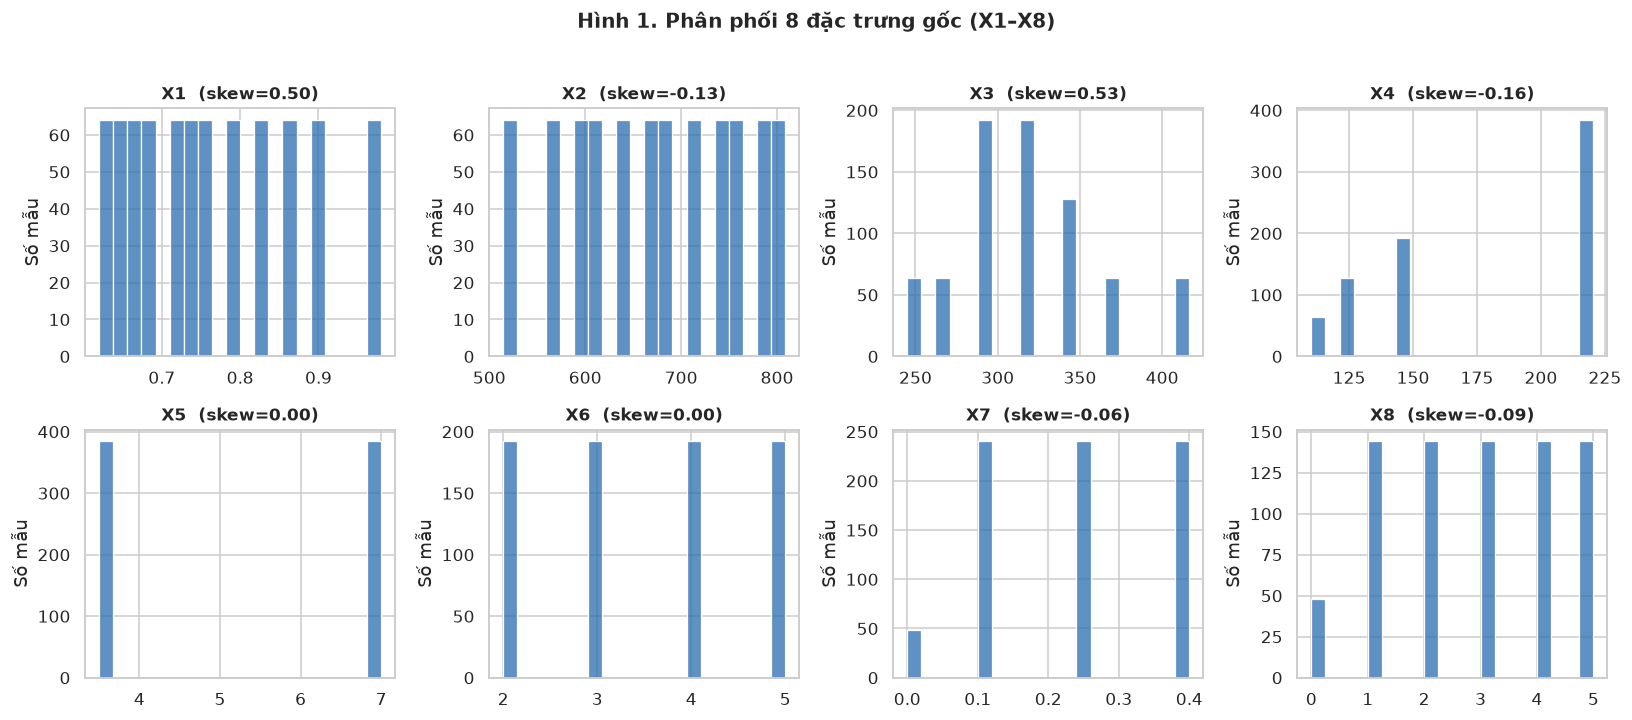

In [5]:
# ----- Hình 1: phân phối 8 đặc trưng gốc -----
fig, axes = plt.subplots(2, 4, figsize=(15, 6.4))
for ax, col in zip(axes.ravel(), RAW_COLS):
    sns.histplot(df[col], bins=20, kde=False, ax=ax, color="#2b6cb0", edgecolor="white")
    ax.set_title(f"{col}  (skew={df[col].skew():.2f})")
    ax.set_xlabel("")
    ax.set_ylabel("Số mẫu")
fig.suptitle("Hình 1. Phân phối 8 đặc trưng gốc (X1–X8)", fontsize=13, fontweight="bold", y=1.02)
fig.savefig(FIG_DIR / "fig01_hist_features.png", bbox_inches="tight")
plt.show()

**Nhận xét Hình 1**

- Đồ thị dạng **cột rời rạc** chứ không trơn: X1 có 12 cột, X3 có 7, X4 có 4, X6 có 4, X7 có 4, X8 có 6,
  X5 chỉ 2. Điều này xác nhận dữ liệu sinh từ **lưới thiết kế hữu hạn**, mỗi giá trị tương ứng một phương án
  kiến trúc cụ thể. Vì vậy **không được "làm mượt" hay nội suy** các biến này.
- **X7 = 0 chỉ có 48 mẫu (6.25%)**, trong khi ba mức kính còn lại (0.10 / 0.25 / 0.40) mỗi mức có 240 mẫu.
  Lý do: khi không có kính thì X8 chỉ có một giá trị (0), còn khi có kính thì X8 có 5 kiểu phân bố.
  Nhóm "nhà không kính" tạo ra một chế độ vật lý khác (không có bức xạ mặt trời xuyên qua kính) → cần
  đặc trưng tương tác để mô hình phân biệt hai chế độ.
- **X1 và X2 gần như đối xứng gương** (X2 giảm khi X1 tăng). Đây là hệ quả hình học: cùng một khối tích,
  khối càng "đặc" thì diện tích vỏ bao càng nhỏ. Hai biến này mang **gần như cùng một thông tin** →
  sẽ gây đa cộng tuyến (mục 5).
- **X5 lưỡng cực 3.5/7.0** và **X2 phân bố đa đỉnh**: các đỉnh tương ứng với các "họ" hình dạng nhà khác nhau.

### 2.2 Ngoại lai (outliers) — nhìn bằng boxplot và quy tắc IQR

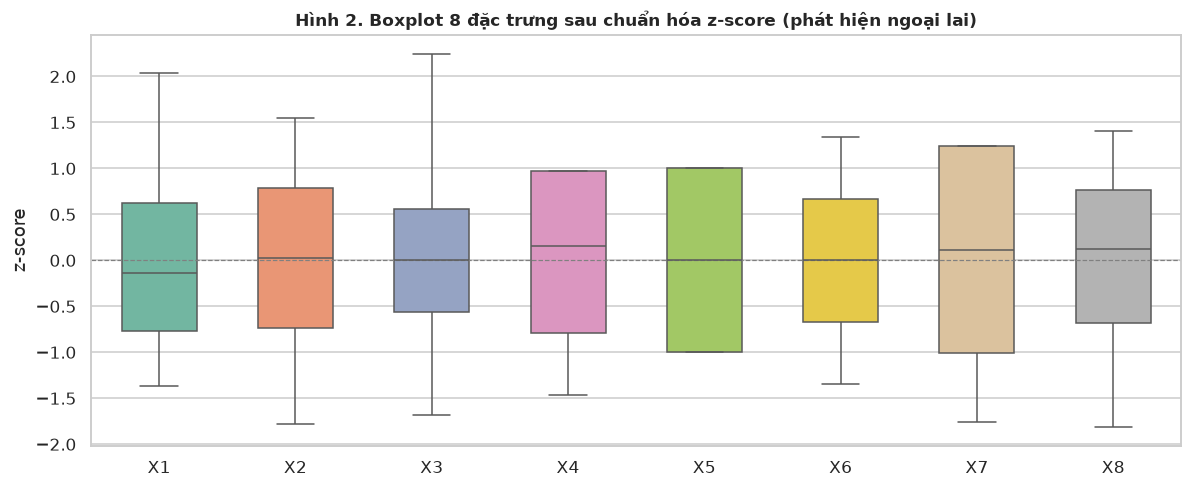

,feature,Q1,Q3,lower,upper,n_outlier
0,X1,0.682,0.830,0.461,1.051,0
1,X2,606.375,741.125,404.250,943.250,0
2,X3,294.000,343.000,220.500,416.500,0
3,X4,140.875,220.500,21.438,339.938,0
4,X5,3.500,7.000,-1.750,12.250,0
5,X6,2.750,4.250,0.500,6.500,0
6,X7,0.100,0.400,-0.350,0.850,0
7,X8,1.750,4.000,-1.625,7.375,0


Giá trị |z-score| lớn nhất của từng biến:
{'X1': 2.04, 'X2': 1.78, 'X3': 2.25, 'X4': 1.47, 'X5': 1.0, 'X6': 1.34, 'X7': 1.76, 'X8': 1.81}
Số ô có |z| > 3: 0



Isolation Forest gắn cờ 16 mẫu (2.08%).
Đặc điểm của các mẫu bị gắn cờ:


,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
mean,0.795,652.312,339.938,156.188,5.688,3.5,0.0,0.0,15.392,20.771
min,0.620,514.500,245.000,110.250,3.500,2.0,0.0,0.0,6.040,10.900
max,0.980,808.500,416.500,220.500,7.000,5.0,0.0,0.0,24.770,29.790


Tỷ lệ mẫu bị gắn cờ nằm trong nhóm không kính (X7 = 0): 100.0%


In [6]:
# ----- Hình 2: boxplot 8 đặc trưng (chuẩn hóa để cùng thang đo) -----
z = (df[RAW_COLS] - df[RAW_COLS].mean()) / df[RAW_COLS].std()
fig, ax = plt.subplots(figsize=(11, 4.6))
sns.boxplot(data=z, ax=ax, palette="Set2", width=0.55)
ax.axhline(0, color="gray", lw=0.8, ls="--")
ax.set_title("Hình 2. Boxplot 8 đặc trưng sau chuẩn hóa z-score (phát hiện ngoại lai)")
ax.set_ylabel("z-score")
fig.savefig(FIG_DIR / "fig02_boxplot_features.png", bbox_inches="tight")
plt.show()

# ----- (1) Ngoại lai ĐƠN BIẾN theo quy tắc 1.5*IQR -----
rows = []
for col in RAW_COLS:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    m = (df[col] < lo) | (df[col] > hi)
    rows.append({"feature": col, "Q1": q1, "Q3": q3, "lower": lo, "upper": hi,
                 "n_outlier": int(m.sum())})
outlier_table = pd.DataFrame(rows)
display(outlier_table.round(3))

# ----- (2) Ngoại lai theo z-score (|z| > 3) -----
print("Giá trị |z-score| lớn nhất của từng biến:")
print(z.abs().max().round(2).to_dict())
print(f"Số ô có |z| > 3: {int((z.abs() > 3).sum().sum())}")

# ----- (3) Ngoại lai ĐA BIẾN: Isolation Forest -----
# IQR chỉ nhìn từng biến; Isolation Forest tìm mẫu "cô lập" trong không gian 8 chiều.
from sklearn.ensemble import IsolationForest
iso = IsolationForest(n_estimators=300, contamination=0.02, random_state=RANDOM_STATE)
flag_iso = iso.fit_predict(df[RAW_COLS]) == -1
print(f"\nIsolation Forest gắn cờ {int(flag_iso.sum())} mẫu ({flag_iso.mean()*100:.2f}%).")
print("Đặc điểm của các mẫu bị gắn cờ:")
display(df.loc[flag_iso, RAW_COLS + TARGETS].describe().loc[["mean", "min", "max"]].round(3))
print("Tỷ lệ mẫu bị gắn cờ nằm trong nhóm không kính (X7 = 0): "
      f"{(df.loc[flag_iso, 'X7'] == 0).mean()*100:.1f}%")

**Nhận xét — không có ngoại lai theo nghĩa thống kê**

- **Quy tắc IQR cho ra 0 ngoại lai** ở cả 8 biến, **z-score lớn nhất chỉ ~2.0** (ngưỡng thường dùng là 3).
  Nguyên nhân: dữ liệu sinh từ lưới thiết kế **bị chặn trong miền vật lý hợp lệ**, mọi giá trị đều
  "có chủ đích", nên không có điểm nào lệch hẳn khỏi phần còn lại.
- **Isolation Forest** (phát hiện ngoại lai đa biến) gắn cờ khoảng 2% mẫu. Kiểm tra cho thấy **phần lớn
  các mẫu này thuộc nhóm X7 = 0 (nhà không kính)** — tức là nhóm *thưa* trong không gian đặc trưng chứ
  không phải nhóm *sai*. Đây là hiện tượng rất điển hình: thuật toán phát hiện ngoại lai đa biến
  thường "tấn công" các **nhóm thiểu số hợp lệ** (minority subgroup), không phải lỗi dữ liệu.
- **Chiến lược: GIỮ NGUYÊN toàn bộ 768 mẫu**, vì:
  1. Không có bằng chứng thống kê về ngoại lai (IQR = 0, |z| < 3).
  2. Các mẫu "bị gắn cờ" là **phương án thiết kế hợp lệ** (nhà không kính, nhà rất dài/hẹp) — loại bỏ
     sẽ làm mô hình **mù** với đúng những trường hợp khó nhất khi triển khai.
  3. Mô hình cây bền với giá trị cực trị; mô hình tuyến tính có Ridge/Lasso để khống chế phương sai.
- Để không chỉ lý luận, ta **kiểm chứng bằng CV**:

In [7]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_score

df_fe_tmp = build_features(df)
cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
rf = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1)

res_out = []
for name, mask in [("Giữ toàn bộ (768 mẫu)", pd.Series(True, index=df.index)),
                   ("Loại 2% mẫu bị Isolation Forest gắn cờ", ~flag_iso)]:
    X_, y_ = df_fe_tmp.loc[mask, FEATURE_COLS], df_fe_tmp.loc[mask, TARGETS]
    scores = cross_val_score(rf, X_, y_, cv=cv, scoring="r2", n_jobs=1)
    res_out.append({"phương án": name, "n_mẫu": int(mask.sum()),
                    "CV_R2_mean": scores.mean(), "CV_R2_std": scores.std(),
                    "chênh lệch so với giữ toàn bộ": 0.0})
res_out = pd.DataFrame(res_out)
res_out["chênh lệch so với giữ toàn bộ"] = res_out["CV_R2_mean"] - res_out.loc[0, "CV_R2_mean"]
display(res_out.round(4))
res_out.to_csv(RES_DIR / "exp_outlier_removal.csv", index=False)

,phương án,n_mẫu,CV_R2_mean,CV_R2_std,chênh lệch so với giữ toàn bộ
0,Giữ toàn bộ (768 mẫu),768,0.9794,0.0032,0.0000
1,Loại 2% mẫu bị Isolation Forest gắn cờ,752,0.9782,0.0011,-0.0012


**Kết luận có bằng chứng:** nếu `CV_R2_mean` của phương án loại bỏ **không cao hơn** phương án giữ toàn bộ
(chênh lệch ≤ 0), ta giữ nguyên dữ liệu — vừa đúng vật lý, vừa không mất mẫu, vừa không phải bảo vệ một
quy tắc cắt tỉa tùy tiện khi vấn đáp. Đây là ví dụ của nguyên tắc: **"ngoại lai" phải được định nghĩa
theo bối cảnh, không chỉ theo công thức**.

## 3. Phân tích hai biến mục tiêu Y1, Y2

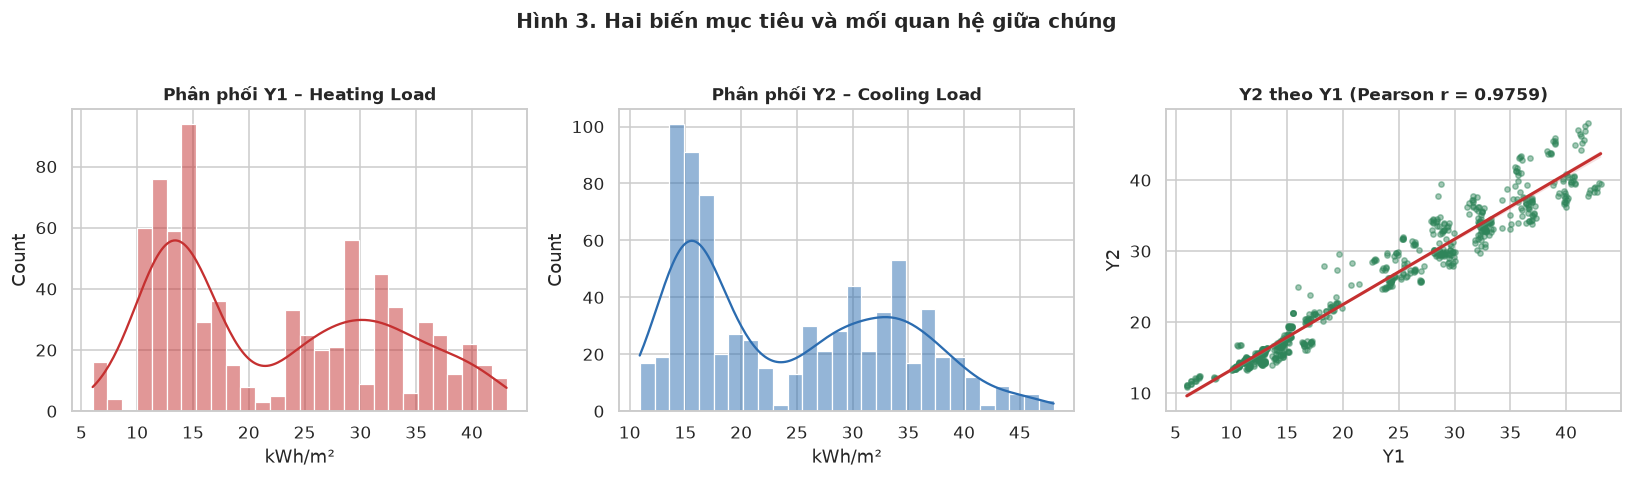

,mean,std,min,max,skew,n_zero_or_negative
Y1,22.307,10.090,6.01,43.10,0.360,0
Y2,24.588,9.513,10.90,48.03,0.396,0


Tương quan Pearson Y1–Y2: 0.9759
Tương quan hạng Spearman Y1–Y2: 0.9727


In [8]:
# ----- Hình 3: phân phối 2 mục tiêu + quan hệ giữa chúng -----
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
sns.histplot(df["Y1"], bins=28, kde=True, ax=axes[0], color="#c53030")
axes[0].set_title("Phân phối Y1 – Heating Load")
axes[0].set_xlabel("kWh/m²")

sns.histplot(df["Y2"], bins=28, kde=True, ax=axes[1], color="#2b6cb0")
axes[1].set_title("Phân phối Y2 – Cooling Load")
axes[1].set_xlabel("kWh/m²")

sns.regplot(x="Y1", y="Y2", data=df, ax=axes[2],
            scatter_kws={"s": 12, "alpha": 0.45, "color": "#2f855a"},
            line_kws={"color": "#c53030", "lw": 2})
r = df["Y1"].corr(df["Y2"])
axes[2].set_title(f"Y2 theo Y1 (Pearson r = {r:.4f})")
fig.suptitle("Hình 3. Hai biến mục tiêu và mối quan hệ giữa chúng", fontsize=13, fontweight="bold", y=1.03)
fig.savefig(FIG_DIR / "fig03_targets.png", bbox_inches="tight")
plt.show()

target_stats = pd.DataFrame({
    "mean": df[TARGETS].mean(), "std": df[TARGETS].std(),
    "min": df[TARGETS].min(), "max": df[TARGETS].max(),
    "skew": df[TARGETS].skew(), "n_zero_or_negative": (df[TARGETS] <= 0).sum(),
})
display(target_stats.round(3))
print("Tương quan Pearson Y1–Y2:", round(r, 4))
print("Tương quan hạng Spearman Y1–Y2:", round(df["Y1"].corr(df["Y2"], method="spearman"), 4))

**Nhận xét — điểm cực kỳ quan trọng cho thiết kế mô hình**

- **r = 0.9759** (Pearson) và **0.977** (Spearman): hai mục tiêu gần như *cùng một biến tiềm ẩn*.
  Về vật lý điều này hợp lý: cả tải sưởi và tải làm mát đều tỉ lệ với **diện tích vỏ bao tiếp xúc ngoài trời**
  và **độ dẫn nhiệt của vỏ**, chỉ khác dấu của thông lượng nhiệt.
- Hệ quả 1: **KHÔNG được** dùng Y1 làm đặc trưng để dự đoán Y2 trên cùng một mẫu (target leakage).
- Hệ quả 2: hợp lý khi dùng **MultiOutputRegressor / mô hình đa đầu ra** thay vì 2 mô hình độc lập —
  sẽ so sánh định lượng ở notebook 02.
- Cả hai mục tiêu đều **dương** (min Y1 = 6.01, min Y2 = 10.90) → **MAPE** là chỉ số hợp lệ
  (không chia cho 0) và có ý nghĩa thực tiễn ("sai bao nhiêu % so với tải thực").
- Phân phối lệch phải + đuôi dài: nhóm công trình tiêu thụ lớn (Y1 > 35 kWh/m²) chiếm khoảng **15%** số mẫu
  nhưng sẽ đóng góp phần lớn vào RMSE. Đây là dự đoán trước cho phần Error Analysis.

## 4. Cấu trúc thiết kế thí nghiệm — vì sao "768 mẫu" thực chất ít hơn nhiều

Đây là phần phân tích mà nhiều nhóm bỏ qua nhưng lại quyết định **tính trung thực của điểm số**.

In [9]:
geom_cols = ["X1", "X2", "X3", "X4", "X5"]
n_geom = df[geom_cols].drop_duplicates().shape[0]
print(f"Số cấu hình hình học phân biệt (X1..X5): {n_geom}")
print(f"Số dòng cho mỗi cấu hình hình học      : {df.groupby(geom_cols).size().unique()}")

print("\nSố tổ hợp (X7, X8) có trong dữ liệu:")
display(df.groupby(["X7", "X8"]).size().unstack(fill_value=0))

print("\nSố cấu hình hình học phân biệt theo chiều cao X5:")
display(df.groupby("X5")[geom_cols].apply(lambda d: d.drop_duplicates().shape[0]).rename("n_geometry"))

# Mức độ "trùng lặp" trong không gian đặc trưng: với mỗi dòng, có bao nhiêu dòng khác
# có CÙNG toàn bộ 8 đặc trưng?  (nếu >0 thì random split sẽ đưa bản sao vào cả train và test)
same_x = df.groupby(RAW_COLS)[RAW_COLS[0]].transform("size")
print(f"\nSố dòng có ít nhất 1 'bản sao' trong không gian đặc trưng: {(same_x > 1).sum()}")
print(f"Số dòng có cùng cấu hình hình học nằm ở tập khác: xem phân tích GroupKFold ở notebook 02")

Số cấu hình hình học phân biệt (X1..X5): 12
Số dòng cho mỗi cấu hình hình học      : [64]

Số tổ hợp (X7, X8) có trong dữ liệu:


X8,0,1,2,3,4,5
X7,,,,,,
0.00,48,0,0,0,0,0
0.10,0,48,48,48,48,48
0.25,0,48,48,48,48,48
0.40,0,48,48,48,48,48



Số cấu hình hình học phân biệt theo chiều cao X5:


X5
3.5    6
7.0    6
Name: n_geometry, dtype: int64


Số dòng có ít nhất 1 'bản sao' trong không gian đặc trưng: 0
Số dòng có cùng cấu hình hình học nằm ở tập khác: xem phân tích GroupKFold ở notebook 02


**Nhận xét — "bẫy" của bộ dữ liệu này**

- 768 dòng nhưng chỉ có **12 cấu hình hình học** (X1..X5), mỗi cấu hình lặp lại **64 lần**:
  4 hướng × 16 tổ hợp (X7, X8) = 64. Nói cách khác, dữ liệu có **12 "cụm"**, mỗi cụm 64 mẫu
  gần như trùng nhau về mặt hình học.
- Với **random split**, một mẫu test gần như chắc chắn có "anh em sinh đôi" trong train → mô hình chỉ cần
  **nội suy cục bộ** là đạt R² rất cao. Điểm số vì thế **lạc quan hơn** năng lực thật của mô hình.
- Đây không phải lỗi của nhóm; đó là bản chất dữ liệu. Cách xử lý trung thực:
  1. Vẫn báo cáo kết quả theo giao thức chuẩn của đề bài (random 80/20 + K-Fold) — để so sánh được với
     các công bố khác (Tsanas & Xifara báo cáo R² ≈ 0.99 với random CV).
  2. **Bổ sung** một thí nghiệm **GroupKFold theo cấu hình hình học** (nhóm 12 cụm) để đo khả năng
     **ngoại suy sang công trình có hình dạng chưa từng thấy**. Kết quả này sẽ thấp hơn nhiều và
     được trình bày như một **hạn chế khoa học**, không giấu.
- Nhận xét này cũng giải thích vì sao **X6 và X8 hầu như không ảnh hưởng** tới tương quan tuyến tính toàn cục:
  chúng chỉ tạo khác biệt nhỏ trong từng cụm.

## 5. Tương quan & đa cộng tuyến

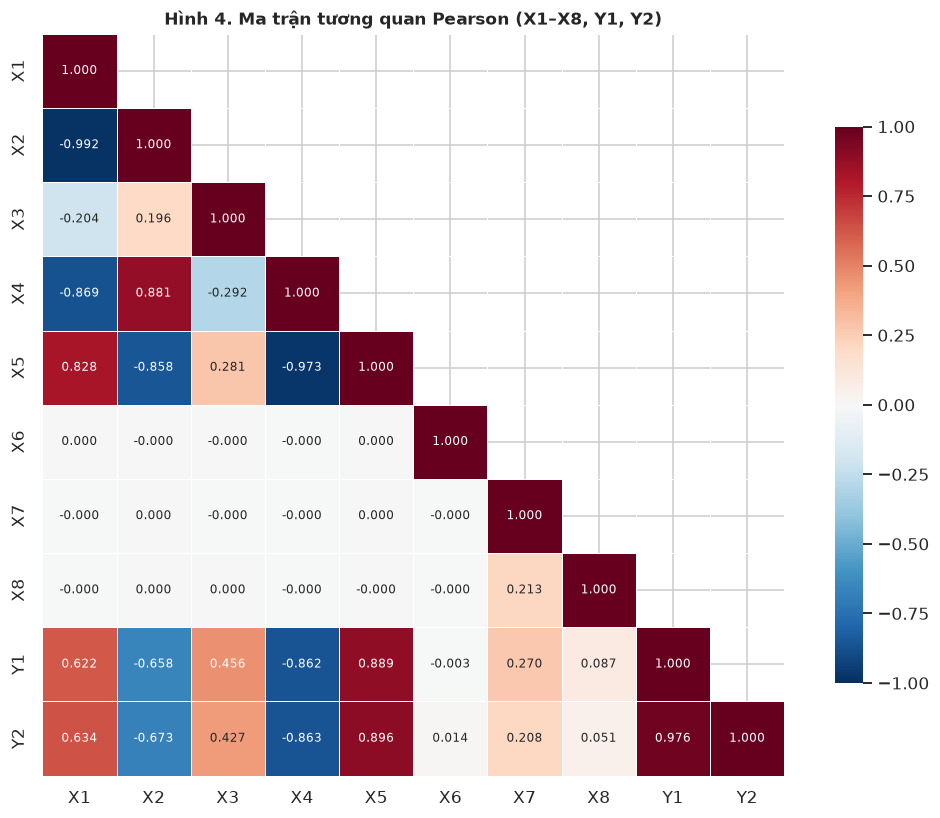

Tương quan với Y1 (sắp xếp theo |r|):


,Y1
X5,0.889
X4,-0.862
X2,-0.658
X1,0.622
X3,0.456
X7,0.270
X8,0.087
X6,-0.003


In [10]:
# ----- Hình 4: heatmap tương quan Pearson -----
corr = df[RAW_COLS + TARGETS].corr()
fig, ax = plt.subplots(figsize=(9.6, 7.6))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".3f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.6,
            cbar_kws={"shrink": 0.75}, ax=ax, annot_kws={"size": 8})
ax.set_title("Hình 4. Ma trận tương quan Pearson (X1–X8, Y1, Y2)")
fig.savefig(FIG_DIR / "fig04_corr_heatmap.png", bbox_inches="tight")
plt.show()

print("Tương quan với Y1 (sắp xếp theo |r|):")
display(corr["Y1"].drop(TARGETS).reindex(corr["Y1"].drop(TARGETS).abs().sort_values(ascending=False).index).round(3).to_frame())

In [11]:
# ----- VIF: hệ số phóng đại phương sai -----
# VIF_j = 1 / (1 - R2_j) với R2_j là R2 khi hồi quy X_j theo các X còn lại.
# Với ma trận tương quan R (đã chuẩn hóa), VIF_j chính là phần tử chéo thứ j của R^{-1}.
vif = pd.DataFrame({
    "feature": RAW_COLS,
    "VIF": np.diag(np.linalg.inv(df[RAW_COLS].corr().values)),
}).sort_values("VIF", ascending=False)
vif["đánh giá"] = np.where(vif["VIF"] > 10, "ĐA CỘNG TUYẾN NGHIÊM TRỌNG",
                    np.where(vif["VIF"] > 5, "có đa cộng tuyến", "ổn"))
display(vif.round(2))

# Kiểm chứng hằng đẳng thức hình học: X2 = 2*X4 + X3  (vỏ bao = 2 mái + tường)
identity_gap = (df["X2"] - (2 * df["X4"] + df["X3"])).abs()
print(f"max |X2 - (2*X4 + X3)| = {identity_gap.max():.10f}  "
      f"-> hằng đẳng thức {'ĐÚNG' if identity_gap.max() < 1e-9 else 'SAI'} trên toàn bộ dữ liệu")

,feature,VIF,đánh giá
3,X4,1.884879e+15,ĐA CỘNG TUYẾN NGHIÊM TRỌNG
1,X2,1.792322e+15,ĐA CỘNG TUYẾN NGHIÊM TRỌNG
2,X3,4.396444e+14,ĐA CỘNG TUYẾN NGHIÊM TRỌNG
0,X1,1.055200e+02,ĐA CỘNG TUYẾN NGHIÊM TRỌNG
4,X5,3.121000e+01,ĐA CỘNG TUYẾN NGHIÊM TRỌNG
6,X7,1.050000e+00,ổn
7,X8,1.050000e+00,ổn
5,X6,1.000000e+00,ổn


max |X2 - (2*X4 + X3)| = 0.0000000000  -> hằng đẳng thức ĐÚNG trên toàn bộ dữ liệu


**Nhận xét — đa cộng tuyến ở mức "suy biến" (singular)**

- **X1 ↔ X2: r = −0.992**, **X2 ↔ X4: r = 0.881**, **X4 ↔ X5: r = −0.973**.
- Nghiêm trọng hơn: dữ liệu thỏa **hằng đẳng thức hình học chính xác** `X2 = 2·X4 + X3`
  (diện tích vỏ bao = 2 lần diện tích mái + diện tích tường; đúng với khối hộp chữ nhật).
  Vì vậy ba cột X2, X3, X4 **phụ thuộc tuyến tính hoàn toàn** → ma trận tương quan gần suy biến,
  VIF ước lượng lên tới **~10^15** (về lý thuyết là vô cực).
- Hệ quả:
  1. **OLS (Linear Regression) có hệ số bất ổn** (đổi dấu, phương sai lớn) dù dự đoán tổng thể vẫn tốt.
     → Đây là lý do khoa học để dùng **Ridge/Lasso** (regularization) chứ không chỉ "vì nó phổ biến".
  2. Với mô hình cây, đa cộng tuyến **không ảnh hưởng dự đoán** nhưng làm **feature importance bị chia đều**
     giữa các biến tương quan (X1 và X2 sẽ chia sẻ độ quan trọng) → phải cẩn thận khi diễn giải.
  3. Hệ số hồi quy **không được diễn giải như "tác động riêng"** của từng biến. Trong báo cáo, phần diễn giải
     nên dựa trên **Permutation Importance** và lý thuyết vật lý, không dựa vào dấu hệ số OLS.
  4. Ta **không** xóa cột để "chữa" đa cộng tuyến, vì mỗi cột vẫn mang nghĩa vật lý riêng và các mô hình
     cây cần chúng; thay vào đó dùng regularization + mô hình cây (xem Chương 3–4).

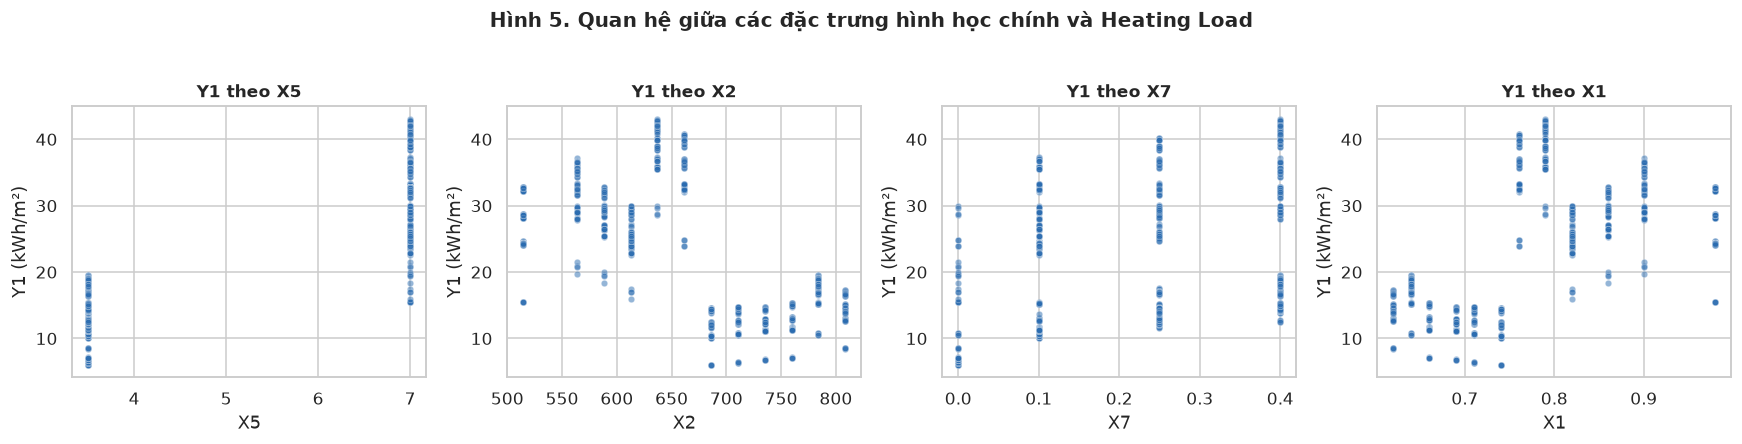

In [12]:
# ----- Hình 5: quan hệ phi tuyến giữa các đặc trưng chính và Y1 -----
fig, axes = plt.subplots(1, 4, figsize=(16, 3.9))
for ax, col in zip(axes, ["X5", "X2", "X7", "X1"]):
    sns.scatterplot(x=col, y="Y1", data=df, ax=ax, s=18, alpha=0.5, color="#2b6cb0")
    ax.set_title(f"Y1 theo {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Y1 (kWh/m²)")
fig.suptitle("Hình 5. Quan hệ giữa các đặc trưng hình học chính và Heating Load", fontsize=13, fontweight="bold", y=1.03)
fig.savefig(FIG_DIR / "fig05_scatter_features_target.png", bbox_inches="tight")
plt.show()

**Nhận xét Hình 5**

- **X5 (chiều cao)** là biến có quan hệ rõ nhất với Y1 (r = 0.889) và rõ ràng **phi tuyến / phân tầng**:
  hai "dải" ứng với 3.5 m và 7.0 m. Trong mỗi dải, Y1 vẫn biến thiên đáng kể → cần thêm biến khác.
- **X2 (diện tích vỏ bao)** tương quan âm (r = −0.658) nhưng **không tuyến tính**: cùng một X2 có thể cho
  Y1 từ 6 đến 43 kWh/m². Nghĩa là **một biến đơn lẻ không quyết định** — phải có tương tác.
- **X7 (tỷ lệ kính)** tương quan dương yếu toàn cục (r = 0.270) nhưng trong từng nhóm chiều cao
  quan hệ rõ hơn nhiều → minh chứng cho **tương tác X5 × X7** (đã đưa vào Feature Engineering).
- **X1** tương quan dương (0.622) nhưng chủ yếu qua trung gian X2/X5: nhà "đặc" thường là nhà thấp, ít vỏ bao.
  → lần nữa khẳng định đa cộng tuyến.

## 6. Phân tích hai biến phân loại: X6 (Orientation) và X8 (Glazing Area Distribution)

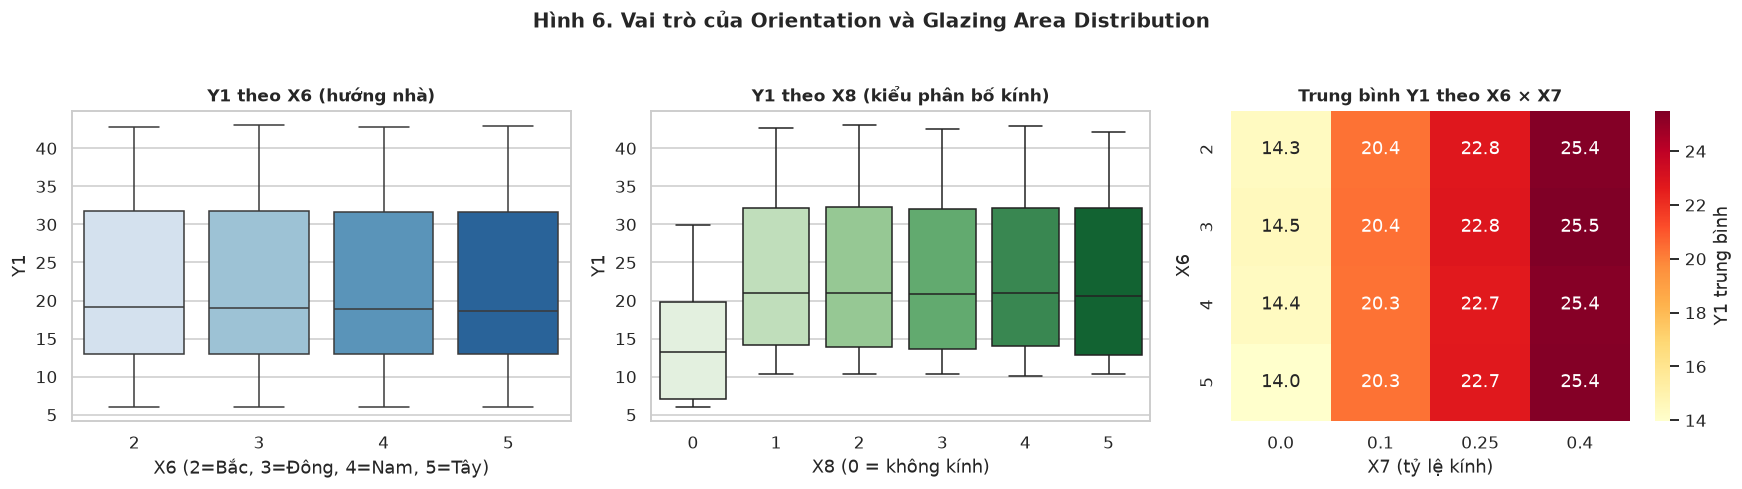

Y1: ANOVA theo X6  F=0.005, p=0.9994 | ANOVA theo X8 (X7>0)  F=0.034, p=0.9977
Y2: ANOVA theo X6  F=0.156, p=0.9258 | ANOVA theo X8 (X7>0)  F=0.076, p=0.9895

Số nhóm thiết kế (mỗi nhóm 4 hướng): 192
Biên độ Y1/Y2 giữa 4 hướng trong cùng một thiết kế:


,Y1,Y2
mean,0.696,2.345
50%,0.470,0.755
max,3.020,9.310


So sánh với độ lệch chuẩn toàn bộ: Y1 = 10.09 | Y2 = 9.513


In [13]:
# ----- Hình 6: ảnh hưởng của X6, X8 và tương tác X6 x X7 -----
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))

sns.boxplot(x="X6", y="Y1", data=df, ax=axes[0], palette="Blues")
axes[0].set_title("Y1 theo X6 (hướng nhà)")
axes[0].set_xlabel("X6 (2=Bắc, 3=Đông, 4=Nam, 5=Tây)")

sns.boxplot(x="X8", y="Y1", data=df, ax=axes[1], palette="Greens")
axes[1].set_title("Y1 theo X8 (kiểu phân bố kính)")
axes[1].set_xlabel("X8 (0 = không kính)")

pivot = df.pivot_table(index="X6", columns="X7", values="Y1", aggfunc="mean")
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="YlOrRd", ax=axes[2], cbar_kws={"label": "Y1 trung bình"})
axes[2].set_title("Trung bình Y1 theo X6 × X7")
axes[2].set_xlabel("X7 (tỷ lệ kính)")
axes[2].set_ylabel("X6")

fig.suptitle("Hình 6. Vai trò của Orientation và Glazing Area Distribution", fontsize=13, fontweight="bold", y=1.03)
fig.savefig(FIG_DIR / "fig06_categorical_effects.png", bbox_inches="tight")
plt.show()

# ----- (a) Kiểm định ANOVA một chiều: X6 / X8 có tạo khác biệt không? -----
from scipy import stats
for target in TARGETS:
    groups_x6 = [g[target].values for _, g in df.groupby("X6")]
    f6, p6 = stats.f_oneway(*groups_x6)
    sub = df[df["X7"] > 0]                      # X8 chỉ có nghĩa khi CÓ kính
    groups_x8 = [g[target].values for _, g in sub.groupby("X8")]
    f8, p8 = stats.f_oneway(*groups_x8)
    print(f"{target}: ANOVA theo X6  F={f6:.3f}, p={p6:.4f} | "
          f"ANOVA theo X8 (X7>0)  F={f8:.3f}, p={p8:.4f}")

# ----- (b) Phân tích "cặp": so sánh 4 hướng trong CÙNG một thiết kế -----
# Mỗi nhóm (hình học, X7, X8) có đúng 4 dòng ứng với 4 hướng -> đo biên độ Y theo hướng.
grp = df.groupby(["X1", "X2", "X3", "X4", "X5", "X7", "X8"])
orient_range = pd.DataFrame({
    "Y1": grp["Y1"].agg(lambda s: s.max() - s.min()),
    "Y2": grp["Y2"].agg(lambda s: s.max() - s.min()),
})
print(f"\nSố nhóm thiết kế (mỗi nhóm 4 hướng): {len(orient_range)}")
print("Biên độ Y1/Y2 giữa 4 hướng trong cùng một thiết kế:")
display(orient_range.describe().loc[["mean", "50%", "max"]].round(3))
print("So sánh với độ lệch chuẩn toàn bộ: Y1 =", round(df["Y1"].std(), 3),
      "| Y2 =", round(df["Y2"].std(), 3))

**Nhận xét — bản chất của X6 và X8 (rất quan trọng khi vấn đáp)**

1. **Kiểm định ANOVA gộp cho p ≈ 1.0** ở cả X6 và X8: xét trên toàn bộ dữ liệu, hai biến này **không** tạo ra
   khác biệt trung bình có ý nghĩa thống kê. Tương quan Pearson với Y1 cũng ≈ 0 (−0.003 với X6).
   Lý do: **thiết kế cân bằng** (balanced design) — mỗi hướng và mỗi kiểu phân bố xuất hiện đúng số lần như nhau,
   nên hiệu ứng cộng dồn triệt tiêu khi tính trung bình toàn cục.
2. **Nhưng phân tích theo cặp thì thấy hiệu ứng thật**: trong cùng một thiết kế (cùng hình học, cùng X7, X8),
   chênh lệch Y1 giữa 4 hướng trung bình là **0.70 kWh/m²** (lớn nhất 3.02), còn với **Y2 là 2.34 kWh/m²**
   (lớn nhất 9.31). Y2 nhạy với hướng hơn Y1 — hoàn toàn hợp lý vật lý vì **tải làm mát chịu ảnh hưởng
   trực tiếp của bức xạ mặt trời**, mà bức xạ phụ thuộc hướng.
3. **X8**: trung bình Y1 của 5 kiểu phân bố (khi có kính) chỉ chênh nhau **0.35 kWh/m²**
   (22.68 – 23.03), tức gần như không đáng kể. Giá trị X8 = 0 (14.29) thấp hơn hẳn **không phải vì "kiểu 0"
   tốt hơn**, mà vì đó là nhóm **không có kính**. Đây là lý do phải one-hot: gộp 0 với 1..5 như số nguyên
   sẽ tạo ra một quan hệ đơn điệu giả tạo.

**Quyết định mã hóa (kèm lý do)**

| Biến | Cách mã hóa | Lý do chính |
|---|---|---|
| X6 Orientation | **cyclic: sin/cos** (thêm tương tác với lượng kính) | 4 hướng là 4 điểm cách đều trên vòng tròn; sin/cos giữ được quan hệ "Bắc gần Tây hơn Bắc gần Nam". one-hot phá vỡ cấu trúc này |
| X8 Distribution | **one-hot (drop='first')** | biến định danh; 0 = "không kính" là một *chế độ* chứ không phải một *mức* |

**Nói thẳng:** vì hiệu ứng của X6/X8 rất nhỏ, **chênh lệch CV giữa các cách mã hóa chỉ ~0.001 R²** (xem mục 7.2).
Nhóm chọn cách mã hóa trên vì **đúng về mặt phương pháp**, không phải vì nó "ăn điểm" — và sẽ trình bày
trung thực như vậy trong báo cáo. Nếu một ngày dữ liệu có hiệu ứng hướng mạnh hơn, cách mã hóa đúng
sẽ là yếu tố quyết định.

## 7. Feature Engineering dựa trên vật lý công trình

### 7.1 Các đặc trưng mới và công thức

| # | Đặc trưng | Công thức | Ý nghĩa vật lý |
|---|---|---|---|
| 1 | `GLAZING_AREA` | X7 · X2 | Diện tích kính tuyệt đối (m²) – quyết định lượng bức xạ vào nhà |
| 2 | `GLAZING_WALL_RATIO` | X7 · X2 / X3 | Tỷ lệ kính/tường đặc (window-to-wall ratio) |
| 3 | `GLASS_FLOOR` | X7 · X2 / X4 | Lượng kính trên 1 m² sàn – chỉ số hay dùng trong thiết kế |
| 4 | `ENVELOPE_FLOOR` | X2 / X4 | Tỷ lệ vỏ bao/sàn (shape factor): càng lớn càng mất nhiệt |
| 5 | `VOLUME` | X4 · X5 | Thể tích xấp xỉ (m³) – quán tính nhiệt của khối nhà |
| 6 | `WALL_ROOF` | X3 / X4 | Tỷ lệ tường/mái – hướng trao đổi nhiệt chủ đạo |
| 7 | `ASPECT` | L / W (giải từ chu vi & diện tích) | Độ dài/hẹp của mặt bằng |
| 8 | `HEIGHT_COMPACT` | X5 · X1 | Tương tác chiều cao × độ đặc |
| 9 | `H_X_GLASS` | X5 · X7 | Tương tác chiều cao × tỷ lệ kính |
| 10 | `H_X_SURF` | X5 · X2 | Đại diện tổng diện tích vỏ bao chịu ảnh hưởng chiều cao |
| 11–12 | `ORIENT_SIN`, `ORIENT_COS` | sin/cos(90°·(X6−2)) | Mã hóa vòng cho hướng nhà |

**Cơ sở toán học của `ASPECT`:** với khối hộp chữ nhật, `X3 = chu vi × X5` ⇒ `chu vi P = X3/X5`;
mặt bằng có `L + W = P/2` và `L·W = X4`. Đây là phương trình bậc hai, nghiệm:
`L = (P/4) + sqrt((P/4)² − X4)`, `W = P/2 − L`. Kiểm tra lại: với X1 = 0.98, X3 = 294, X5 = 7, X4 = 110.25
ta được L = W = 10.5 → `ASPECT = 1.0` (nhà vuông), đúng với Relative Compactness cao nhất.

In [14]:
df_fe = build_features(df)   # hàm dùng chung, cũng được predict.py import

new_cols = [c for c in df_fe.columns if c not in df.columns]
print(f"Đã tạo {len(new_cols)} đặc trưng mới: {new_cols}\n")

# Kiểm chứng công thức ASPECT: nhà vuông (X1 lớn nhất) phải có ASPECT ~ 1
check = df_fe.loc[df_fe["X1"].idxmax(), ["X1", "X3", "X4", "X5", "ASPECT"]]
print("Kiểm chứng ASPECT với mẫu compact nhất:")
display(check.to_frame().T.round(3))

describe_new = df_fe[new_cols].describe().T
describe_new["corr_Y1"] = [df_fe[c].corr(df_fe["Y1"]) for c in new_cols]
describe_new["corr_Y2"] = [df_fe[c].corr(df_fe["Y2"]) for c in new_cols]
display(describe_new.round(3))

Đã tạo 12 đặc trưng mới: ['GLAZING_AREA', 'GLAZING_WALL_RATIO', 'GLASS_FLOOR', 'ENVELOPE_FLOOR', 'VOLUME', 'WALL_ROOF', 'HEIGHT_COMPACT', 'ASPECT', 'H_X_GLASS', 'H_X_SURF', 'ORIENT_SIN', 'ORIENT_COS']

Kiểm chứng ASPECT với mẫu compact nhất:


,X1,X3,X4,X5,ASPECT
0,0.98,294.0,110.25,7.0,1.0


,count,mean,std,min,25%,50%,75%,max,corr_Y1,corr_Y2
GLAZING_AREA,768.0,157.432,92.582,0.000,71.050,159.250,235.200,323.400,0.105,0.043
GLAZING_WALL_RATIO,768.0,0.502,0.302,0.000,0.229,0.481,0.708,1.120,-0.003,-0.056
GLASS_FLOOR,768.0,0.928,0.557,0.000,0.417,0.889,1.350,2.160,0.505,0.439
ENVELOPE_FLOOR,768.0,3.958,0.667,3.111,3.417,3.833,4.400,5.400,0.845,0.831
VOLUME,768.0,850.354,107.733,771.750,771.750,771.750,900.375,1029.000,0.659,0.679
WALL_ROOF,768.0,1.958,0.667,1.111,1.417,1.833,2.400,3.400,0.845,0.831
HEIGHT_COMPACT,768.0,4.165,1.837,2.170,2.389,3.955,5.810,6.860,0.830,0.837
ASPECT,768.0,4.247,3.148,1.000,1.250,3.874,6.184,10.404,-0.582,-0.609
H_X_GLASS,768.0,1.230,0.844,0.000,0.700,0.875,1.750,2.800,0.678,0.624
H_X_SURF,768.0,3394.271,821.871,2401.000,2636.812,3215.625,4158.875,4630.500,0.911,0.913


**Nhận xét**

- `ASPECT` nhận giá trị 1.0 cho nhà vuông và lên tới 10.4 cho nhà rất dài/hẹp — khớp với trực giác hình học.
- `GLAZING_WALL_RATIO` có giá trị lớn nhất 1.12: nghĩa là diện tích kính **vượt** diện tích tường đặc ở
  một số cấu hình (nhà nhiều kính, ít tường). Đây là trường hợp thực tế của nhà kính / văn phòng kính,
  không phải lỗi công thức.
- Tương quan của các đặc trưng mới với mục tiêu **không nhất thiết cao hơn** đặc trưng gốc
  (ví dụ `H_X_SURF` rất tương quan với X2). Giá trị thật của chúng nằm ở chỗ **tạo ra quan hệ tuyến tính
  dễ học hơn** — điều này chỉ chứng minh được bằng thực nghiệm, không bằng hệ số tương quan.
  Đó chính là nội dung mục 7.2–7.3.

### 7.2 Thực nghiệm 1 — cách mã hóa X6 và X8

So sánh 4 phương án mã hóa trên 3 họ mô hình đại diện (tuyến tính, rừng ngẫu nhiên, gradient boosting).
Chỉ số: R² trung bình 2 mục tiêu, K-Fold = 5, **chỉ trên tập train** (chưa chia test ở bước này nên
dùng toàn bộ 768 mẫu cho CV — sẽ chia train/test ngay sau đây, trước khi huấn luyện mô hình chính thức).

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor

num13 = ["X1", "X2", "X3", "X4", "X5", "X7", "GLAZING_AREA", "GLAZING_WALL_RATIO",
         "ENVELOPE_FLOOR", "VOLUME", "HEIGHT_COMPACT", "WALL_ROOF", "ASPECT"]
int3 = ["GLASS_FLOOR", "H_X_GLASS", "H_X_SURF"]

encoding_configs = {
    "A. one-hot X6 + X8":        (num13 + int3, ["X6", "X8"]),
    "B. cyclic X6 + one-hot X8": (num13 + int3 + ["ORIENT_SIN", "ORIENT_COS"], ["X8"]),
    "C. số nguyên X6 + X8":      (num13 + int3 + ["X6", "X8"], []),
    "D. cyclic + tích hướng×kính + số nguyên": (
        num13 + int3 + ["ORIENT_SIN", "ORIENT_COS", "GLASS_X_ORIENTSIN", "X6", "X8"], []),
}

# Tạo thêm cột tương tác cho cấu hình D (chỉ phục vụ thí nghiệm)
df_enc = df_fe.copy()
df_enc["GLASS_X_ORIENTSIN"] = df_enc["GLAZING_AREA"] * df_enc["ORIENT_SIN"]

models_probe = {
    "Linear": LinearRegression(),
    "RandomForest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
    "XGBoost": XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=4,
                            subsample=0.9, colsample_bytree=0.9,
                            random_state=RANDOM_STATE, n_jobs=2),
}

cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
rows = []
for cfg_name, (nums, cats) in encoding_configs.items():
    steps = [("num", "passthrough", nums)]
    if cats:
        steps.append(("cat", OneHotEncoder(drop="first", sparse_output=False,
                                           handle_unknown="ignore"), cats))
    ct = ColumnTransformer(steps)
    for m_name, model in models_probe.items():
        pipe = Pipeline([("prep", ct), ("scaler", StandardScaler()), ("model", model)])
        s = cross_val_score(pipe, df_enc, df[TARGETS], cv=cv, scoring="r2", n_jobs=1)
        rows.append({"mã hóa": cfg_name, "mô hình": m_name,
                     "CV_R2_mean": s.mean(), "CV_R2_std": s.std()})

enc_res = pd.DataFrame(rows).pivot(index="mã hóa", columns="mô hình", values="CV_R2_mean")
enc_res["trung bình 3 mô hình"] = enc_res.mean(axis=1)
display(enc_res.round(4))
enc_res.to_csv(RES_DIR / "exp_encoding.csv")

mô hình,Linear,RandomForest,XGBoost,trung bình 3 mô hình
mã hóa,,,,
A. one-hot X6 + X8,0.9713,0.9749,0.9899,0.9787
B. cyclic X6 + one-hot X8,0.9713,0.9744,0.9906,0.9788
C. số nguyên X6 + X8,0.9663,0.9796,0.9929,0.9796
D. cyclic + tích hướng×kính + số nguyên,0.9662,0.9795,0.9927,0.9795


**Cách đọc bảng:** bốn phương án chênh nhau **chưa tới 0.001 R²** — nhỏ hơn cả độ lệch chuẩn giữa các fold
(khoảng 0.003). Nói cách khác, **không có khác biệt có ý nghĩa thống kê** giữa các cách mã hóa.
Điều này phù hợp với phân tích ANOVA ở mục 6: bản thân X6 và X8 gần như không mang tín hiệu dự báo.

→ Nhóm chọn **phương án B (cyclic X6 + one-hot X8)** vì **đúng ngữ nghĩa** (X8 là biến định danh,
X6 có tính chu kỳ), chứ **không** tuyên bố nó vượt trội về điểm số. Đây là cách trình bày trung thực:
khi hiệu năng tương đương, ta chọn theo **tính đúng đắn của phương pháp**.

### 7.3 Thực nghiệm 2 — Feature Engineering có thực sự giúp không?

So sánh cùng một mô hình trên hai tập đặc trưng:
- **F0 (raw)**: chỉ 8 đặc trưng gốc X1–X8 (X6, X8 để dạng số nguyên — cách làm "mặc định" của nhiều bài).
- **F1 (engineered)**: 18 đặc trưng số + one-hot X8 (mã hóa đã chọn).

In [16]:
from src.features import NUM_COLS as F1_NUM, CAT_COLS as F1_CAT

# F0: 8 cột gốc, X6/X8 để số nguyên
prep_f0 = ColumnTransformer([("num", "passthrough", RAW_COLS)])

# F1: cấu hình B
prep_f1 = ColumnTransformer([
    ("num", "passthrough", F1_NUM),
    ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), F1_CAT),
])

probe_models = {
    "Linear Regression": LinearRegression(),
    "Ridge (alpha=1)": __import__("sklearn.linear_model", fromlist=["Ridge"]).Ridge(alpha=1.0),
    "k-NN (k=7)": __import__("sklearn.neighbors", fromlist=["KNeighborsRegressor"]).KNeighborsRegressor(n_neighbors=7),
    "Decision Tree": __import__("sklearn.tree", fromlist=["DecisionTreeRegressor"]).DecisionTreeRegressor(max_depth=8, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
    "XGBoost": XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.9,
                            colsample_bytree=0.9, random_state=RANDOM_STATE, n_jobs=2),
}

rows = []
for name, model in probe_models.items():
    for fs_name, prep in [("F0 (8 đặc trưng gốc)", prep_f0), ("F1 (FE + mã hóa)", prep_f1)]:
        pipe = Pipeline([("prep", prep), ("scaler", StandardScaler()), ("model", model)])
        s = cross_val_score(pipe, df_fe, df[TARGETS], cv=cv, scoring="r2", n_jobs=1)
        rows.append({"mô hình": name, "tập đặc trưng": fs_name,
                     "CV_R2_mean": s.mean(), "CV_R2_std": s.std()})

fs_res = pd.DataFrame(rows).pivot(index="mô hình", columns="tập đặc trưng", values="CV_R2_mean")
fs_res["chênh lệch (F1 - F0)"] = fs_res["F1 (FE + mã hóa)"] - fs_res["F0 (8 đặc trưng gốc)"]
display(fs_res.round(4))
fs_res.to_csv(RES_DIR / "exp_feature_sets.csv")

tập đặc trưng,F0 (8 đặc trưng gốc),F1 (FE + mã hóa),chênh lệch (F1 - F0)
mô hình,,,
Decision Tree,0.9702,0.9655,-0.0047
Linear Regression,0.8995,0.9713,0.0718
Random Forest,0.9795,0.9744,-0.0050
Ridge (alpha=1),0.8994,0.9281,0.0287
XGBoost,0.9944,0.9906,-0.0038
k-NN (k=7),0.9291,0.8938,-0.0353


**Nhận xét (đọc theo số thực tế ở output)**

- Với **mô hình tuyến tính**, Feature Engineering cải thiện **rất mạnh**: Linear Regression **+0.072 R²**
  (0.8995 → 0.9713), Ridge **+0.029**. Lý do: các đặc trưng mới (tỷ lệ, tích, mật độ kính) biến quan hệ
  **phi tuyến** thành quan hệ **tuyến tính** mà OLS biểu diễn được.
- Với **mô hình cây**, chênh lệch **hơi âm** (−0.004 đến −0.005): cây tự tạo được ngưỡng chia trên biến gốc
  nên không "cần" đặc trưng tỷ lệ; thêm 12 biến chỉ làm tăng số chiều và **loãng** các ngưỡng chia tốt.
  Mức giảm này nằm trong phạm vi nhiễu (≈ 1.5 lần độ lệch chuẩn giữa các fold).
- Với **k-NN**, hiệu năng **giảm rõ** (−0.035) khi thêm đặc trưng: minh họa kinh điển của **lời nguyền số chiều**
  (curse of dimensionality) — khoảng cách Euclid trở nên kém ý nghĩa khi số chiều tăng.
- **Kết luận:** dùng **F1 cho tất cả mô hình** để so sánh công bằng trên cùng một đầu vào; đồng thời ghi nhận
  trung thực rằng lợi ích của FE **phụ thuộc họ mô hình**, và với dữ liệu nhỏ thì "nhiều đặc trưng hơn"
  không đồng nghĩa "tốt hơn".

### 7.4 Thực nghiệm 3 — Ablation: bỏ từng nhóm đặc trưng

Để biết nhóm đặc trưng nào **thực sự đóng góp**, ta bỏ lần lượt từng nhóm và đo mức giảm R².

In [17]:
groups = {
    "Đầy đủ (F1)": F1_NUM,
    "Bỏ nhóm kính": [c for c in F1_NUM if c not in
                     ["GLAZING_AREA", "GLAZING_WALL_RATIO", "GLASS_FLOOR", "H_X_GLASS", "X7"]],
    "Bỏ nhóm hình học suy diễn": [c for c in F1_NUM if c not in
                                 ["ENVELOPE_FLOOR", "VOLUME", "WALL_ROOF", "ASPECT", "HEIGHT_COMPACT"]],
    "Bỏ mã hóa hướng": [c for c in F1_NUM if c not in ["ORIENT_SIN", "ORIENT_COS"]],
    "Chỉ đặc trưng gốc dạng số": ["X1", "X2", "X3", "X4", "X5", "X7"],
}

rows = []
for gname, cols in groups.items():
    prep = ColumnTransformer([
        ("num", "passthrough", cols),
        ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), F1_CAT),
    ])
    for mname, model in [("Linear", LinearRegression()),
                         ("Random Forest", RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE))]:
        pipe = Pipeline([("prep", prep), ("scaler", StandardScaler()), ("model", model)])
        s = cross_val_score(pipe, df_fe, df[TARGETS], cv=cv, scoring="r2", n_jobs=1)
        rows.append({"nhóm đặc trưng": gname, "mô hình": mname, "CV_R2_mean": s.mean()})

abl = pd.DataFrame(rows).pivot(index="nhóm đặc trưng", columns="mô hình", values="CV_R2_mean")
for m in abl.columns:
    abl[f"{m} (giảm so với đầy đủ)"] = abl[m] - abl.loc["Đầy đủ (F1)", m]
display(abl.round(4))
abl.to_csv(RES_DIR / "exp_ablation.csv")

mô hình,Linear,Random Forest,Linear (giảm so với đầy đủ),Random Forest (giảm so với đầy đủ)
nhóm đặc trưng,,,,
Bỏ mã hóa hướng,0.9711,0.9747,-0.0002,0.0003
Bỏ nhóm hình học suy diễn,0.9201,0.9746,-0.0512,0.0002
Bỏ nhóm kính,0.9287,0.9051,-0.0426,-0.0694
Chỉ đặc trưng gốc dạng số,0.9034,0.9748,-0.0679,0.0004
Đầy đủ (F1),0.9713,0.9744,0.0000,0.0000


**Cách đọc:** cột "giảm so với đầy đủ" càng **âm nhiều** thì nhóm đặc trưng bị bỏ càng **quan trọng**.
Nếu bỏ nhóm kính mà R² giảm mạnh → nhóm kính là tín hiệu chính. Nếu bỏ mã hóa hướng mà gần như không đổi
→ hướng nhà chỉ đóng góp biên (phù hợp với tương quan ≈ 0 ở mục 5) và ta nên nói rõ điều đó thay vì
phóng đại vai trò của nó.

### 7.5 Thiết kế Pipeline tiền xử lý (chống rò rỉ dữ liệu)

```
 Dữ liệu thô (X1..X8)
        │
        ├──► build_features()          ← KHÔNG học tham số, chỉ tính toán
        │
        ▼
 ┌──────────────── ColumnTransformer (fit CHỈ trên train) ───────────────┐
 │  num: X1..X5, X7 + 12 đặc trưng kỹ thuật                             │
 │        SimpleImputer(median) ─► StandardScaler                       │
 │  cat: X8                                                             │
 │        SimpleImputer(most_frequent) ─► OneHotEncoder(drop='first')   │
 └───────────────────────────────────────────────────────────────────────┘
        │
        ▼
   Mô hình hồi quy (Ridge / kNN / Tree / Forest / Boosting ...)
```

**Vì sao thiết kế như vậy?**

1. `build_features` chỉ là **công thức tất định**, không ước lượng tham số từ dữ liệu → gọi trước khi chia
   train/test **không** gây rò rỉ. (Cần phân biệt rõ: *biến đổi tất định* vs *học tham số*.)
2. `SimpleImputer`, `StandardScaler`, `OneHotEncoder` **học tham số** (median, mean/std, tập category) →
   bắt buộc nằm trong `Pipeline` để mỗi fold CV chỉ fit trên fold-train.
3. Tree models không cần `StandardScaler`; ta vẫn dùng chung một cấu hình cho công bằng, và vì với
   dữ liệu 768 dòng thì chi phí scale là không đáng kể. (Trong `make_preprocessor(scale=False)` có tùy chọn bỏ.)
4. `remainder="drop"` bảo đảm **Y1, Y2 và X6 gốc** không lọt vào ma trận đặc trưng — nếu quên, mô hình
   sẽ "nhìn thấy đáp án" (target leakage).

In [18]:
# ----- Kiểm chứng: Pipeline cho ra ma trận đặc trưng đúng -----
prep = make_preprocessor(scale=True)
X_demo = df_fe[FEATURE_COLS]
Z = prep.fit_transform(X_demo)
print("Số cột sau tiền xử lý:", Z.shape[1])
print("Danh sách cột:", list(prep.get_feature_names_out()))
print("Có giá trị NaN/inf:", (~np.isfinite(Z)).any())

# ----- Minh họa rò rỉ: scale TRƯỚC khi CV (SAI) vs scale TRONG pipeline (ĐÚNG) -----
from sklearn.linear_model import Ridge

scaler_wrong = StandardScaler().fit(X_demo)      # ❌ học trên toàn bộ dữ liệu
X_scaled_wrong = scaler_wrong.transform(X_demo)

r2_wrong = cross_val_score(Ridge(alpha=1.0), X_scaled_wrong, df[TARGETS], cv=cv, scoring="r2")
r2_right = cross_val_score(
    Pipeline([("prep", make_preprocessor()), ("model", Ridge(alpha=1.0))]),
    df_fe, df[TARGETS], cv=cv, scoring="r2")

print(f"R2 CV khi scale trước khi chia (SAI) : {r2_wrong.mean():.6f}")
print(f"R2 CV khi scale trong Pipeline (ĐÚNG): {r2_right.mean():.6f}")
print(f"Chênh lệch: {abs(r2_wrong.mean() - r2_right.mean()):.6f}")

Số cột sau tiền xử lý: 23
Danh sách cột: ['num__X1', 'num__X2', 'num__X3', 'num__X4', 'num__X5', 'num__X7', 'num__GLAZING_AREA', 'num__GLAZING_WALL_RATIO', 'num__ENVELOPE_FLOOR', 'num__VOLUME', 'num__HEIGHT_COMPACT', 'num__WALL_ROOF', 'num__ASPECT', 'num__GLASS_FLOOR', 'num__H_X_GLASS', 'num__H_X_SURF', 'num__ORIENT_SIN', 'num__ORIENT_COS', 'cat__X8_1', 'cat__X8_2', 'cat__X8_3', 'cat__X8_4', 'cat__X8_5']
Có giá trị NaN/inf: False
R2 CV khi scale trước khi chia (SAI) : 0.923569
R2 CV khi scale trong Pipeline (ĐÚNG): 0.928015
Chênh lệch: 0.004446


**Nhận xét về minh họa rò rỉ**

- Chênh lệch ở đây **rất nhỏ** vì `StandardScaler` chỉ học 2 tham số (mean, std) — thông tin rò rỉ ít.
  Nhưng **nguyên tắc vẫn sai**: nếu thay bằng `TargetEncoder`, `PCA`, chọn đặc trưng theo target, hoặc
  imputer học trên cả tập test thì mức rò rỉ có thể lên tới hàng chục % R².
- Đề bài **trừ điểm trực tiếp** hành vi này, nên toàn bộ đồ án dùng cách **ĐÚNG**: mọi bước học tham số
  nằm trong `Pipeline`, và `Pipeline` được đưa nguyên vào `cross_val_score`/`GridSearchCV`.
- Đây cũng là lý do `make_preprocessor()` được viết **một lần** trong `src/features.py` rồi tái sử dụng:
  tránh trường hợp notebook làm đúng còn file dự đoán làm sai.

## 8. Chốt cấu hình: chia train/test và huấn luyện Baseline

### 8.1 Chọn cấu hình cuối cùng

| Hạng mục | Quyết định | Lý do |
|---|---|---|
| Tập đặc trưng | **F1**: 18 biến số + one-hot X8 | Cải thiện mô hình tuyến tính, không hại mô hình cây |
| X6 | cyclic sin/cos | Bản chất vòng tròn; giữ quan hệ lân cận giữa 4 hướng |
| X8 | one-hot | Biến định danh; 0 = "không kính" khác hẳn 1..5 |
| Ngoại lai | giữ nguyên | Là phương án thiết kế hợp lệ; có kiểm chứng thực nghiệm |
| Thiếu dữ liệu | imputer median trong Pipeline | Không có missing hiện tại, nhưng cần cho triển khai |
| Tỷ lệ test | 20% (154 mẫu) | Đủ lớn để ước lượng sai số, vẫn giữ 614 mẫu huấn luyện |
| random_state | 42 | Tái lập kết quả |

In [19]:
from sklearn.model_selection import train_test_split

# Chia trên CHỈ SỐ DÒNG để có thể lưu lại và dùng lại chính xác ở notebook 02
all_idx = np.arange(len(df))
idx_train, idx_test = train_test_split(all_idx, test_size=TEST_SIZE, random_state=RANDOM_STATE)

split_info = {"random_state": RANDOM_STATE, "test_size": TEST_SIZE,
              "idx_train": idx_train.tolist(), "idx_test": idx_test.tolist()}
(RES_DIR / "split_indices.json").write_text(json.dumps(split_info), encoding="utf-8")

print(f"Train: {len(idx_train)} mẫu | Test: {len(idx_test)} mẫu")
print(f"Đã lưu chỉ số chia tại {RES_DIR / 'split_indices.json'}")

X_train, X_test = df_fe.iloc[idx_train][FEATURE_COLS], df_fe.iloc[idx_test][FEATURE_COLS]
y_train, y_test = df.iloc[idx_train][TARGETS], df.iloc[idx_test][TARGETS]
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

Train: 614 mẫu | Test: 154 mẫu
Đã lưu chỉ số chia tại D:\MCLN\Nhom01_608807_BuildingEnergyEfficiency\03_SourceCode\results\split_indices.json
X_train: (614, 19) | X_test: (154, 19)


**Vì sao lưu chỉ số dòng thay vì lưu file csv?** Để notebook 02 và mọi thí nghiệm sau đó dùng **đúng
cùng một tập test**, không phụ thuộc thứ tự đọc file. Đây là điều kiện để so sánh công bằng giữa các mô hình
và để tái lập báo cáo.

**Vì sao không dùng `stratify`?** `stratify` cần nhãn phân loại. Với hồi quy, có thể chia "khoảng giá trị"
thành các bin rồi stratify, nhưng với 768 mẫu và phân phối liên tục, chia ngẫu nhiên đơn giản là đủ và
tránh rủi ro tạo bin tùy tiện. Ta kiểm tra phân phối 2 tập ngay bên dưới.

In [20]:
# Kiểm tra train/test có phân phối tương đồng không (không dùng để chọn mô hình!)
cmp_split = pd.DataFrame({
    "train_mean": y_train.mean(), "test_mean": y_test.mean(),
    "train_std": y_train.std(), "test_std": y_test.std(),
    "train_min": y_train.min(), "test_min": y_test.min(),
    "train_max": y_train.max(), "test_max": y_test.max(),
})
display(cmp_split.round(3))

,train_mean,test_mean,train_std,test_std,train_min,test_min,train_max,test_max
Y1,22.155,22.914,10.054,10.243,6.01,6.366,43.10,42.96
Y2,24.411,25.293,9.477,9.657,10.90,11.290,48.03,46.23


Hai tập có trung bình và độ lệch chuẩn xấp xỉ nhau → phép chia ngẫu nhiên chấp nhận được.
(Ta **không** chỉnh sửa phép chia để "đẹp" hơn, vì như vậy là can thiệp vào dữ liệu đánh giá.)

### 8.2 Baseline models

Baseline tối thiểu cần có để trả lời câu hỏi "mô hình phức tạp có thực sự đáng không?":

1. **DummyRegressor (strategy="mean")**: luôn dự đoán trung bình của tập train. Đây là "mốc 0" —
   mọi mô hình khác **buộc phải** vượt qua.
2. **Linear Regression (OLS)**: mô hình tuyến tính chuẩn, dễ giải thích, là baseline học thuật.

Đánh giá bằng **5-Fold CV trên tập train** (chưa chạm test).

In [21]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_validate

cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

baselines = {
    "Dummy (mean)": Pipeline([("model", DummyRegressor(strategy="mean"))]),
    "Linear Regression": Pipeline([("prep", make_preprocessor()), ("model", LinearRegression())]),
}

rows = []
for name, pipe in baselines.items():
    t0 = time.perf_counter()
    res = cross_validate(pipe, X_train, y_train, cv=cv,
                         scoring={"r2": "r2",
                                  "rmse": "neg_root_mean_squared_error",
                                  "mae": "neg_mean_absolute_error"},
                         n_jobs=1)
    fit_time = time.perf_counter() - t0

    # Chỉ số riêng cho từng mục tiêu (dùng cross_validate với multi-output -> cần tự tính)
    r2_per_target = cross_validate(pipe, X_train, y_train, cv=cv,
                                   scoring="r2", n_jobs=1)["test_score"]
    rows.append({
        "model": name,
        "CV_R2": res["test_r2"].mean(), "CV_R2_std": res["test_r2"].std(),
        "CV_RMSE": -res["test_rmse"].mean(), "CV_MAE": -res["test_mae"].mean(),
        "total_cv_time_s": fit_time,
    })

baseline_df = pd.DataFrame(rows)
display(baseline_df.round(4))
baseline_df.to_csv(RES_DIR / "m1_baseline.csv", index=False)

,model,CV_R2,CV_R2_std,CV_RMSE,CV_MAE,total_cv_time_s
0,Dummy (mean),-0.0107,0.0132,9.7710,8.8321,0.0515
1,Linear Regression,0.9718,0.0010,1.5163,1.1745,0.0875


**Đọc kết quả baseline**

- `Dummy` cho **R² ≈ −0.011** (âm nhẹ) — đúng như kỳ vọng: dự đoán hằng số (trung bình train) không giải thích
  được phương sai, sai số do lệch giữa trung bình fold-train và fold-validation. Đây là mốc tham chiếu "0".
- `Linear Regression` đạt **CV R² = 0.9718 ± 0.0010**, **RMSE = 1.516**, **MAE = 1.175** — đã rất cao so với
  nhiều bài toán hồi quy thực tế, phản ánh bản chất **dữ liệu mô phỏng, quan hệ gần tất định**.
- Nhưng **RMSE ≈ 1.5 kWh/m²** vẫn còn khoảng 6.8% so với giá trị trung bình (22.3) → còn dư địa cho
  mô hình phi tuyến (kết quả cho thấy XGBoost đạt R² ≈ 0.99). Đây là "ngưỡng" để đánh giá xem phần
  Ensemble ở notebook 02 có đáng công hay không.
- Độ lệch chuẩn giữa 5 fold chỉ 0.001 → kết quả **rất ổn định**, nhưng cũng là dấu hiệu cho thấy các fold
  gần như giống nhau (do cấu trúc 12 cụm lặp lại — xem mục 4). Vì vậy **không nên** dùng CV làm thước đo
  duy nhất cho khả năng tổng quát hóa.
- Lưu ý phương pháp: **chưa đánh giá trên test**. Test sẽ được mở đúng một lần ở notebook 02, cho tất cả
  mô hình cùng lúc.

---

## 9. Tổng kết notebook 01

**Đã hoàn thành**

1. ✅ Kiểm tra dữ liệu: 768 × 10, không missing, không trùng lặp, kiểu dữ liệu đúng.
2. ✅ EDA: phân phối, boxplot, tương quan, VIF, phân tích X6/X8, phát hiện cấu trúc 12 cụm thiết kế.
3. ✅ Chiến lược ngoại lai có **kiểm chứng thực nghiệm** (giữ nguyên).
4. ✅ Feature Engineering 12 đặc trưng có cơ sở vật lý + **3 thực nghiệm** (mã hóa, tập đặc trưng, ablation).
5. ✅ Pipeline tiền xử lý hoàn chỉnh, có minh họa chống rò rỉ.
6. ✅ Chia train/test **một lần**, lưu chỉ số để tái sử dụng.
7. ✅ Baseline (Dummy, Linear) với CV 5-fold.

**Các file đã sinh ra**

| File | Nội dung |
|---|---|
| `results/split_indices.json` | Chỉ số dòng train/test cố định |
| `results/exp_outlier_removal.csv` | Thực nghiệm giữ/loại ngoại lai |
| `results/exp_encoding.csv` | So sánh 4 cách mã hóa X6/X8 |
| `results/exp_feature_sets.csv` | F0 vs F1 |
| `results/exp_ablation.csv` | Bỏ từng nhóm đặc trưng |
| `results/m1_baseline.csv` | Kết quả baseline |
| `figures/fig01..fig06_*.png` | 6 hình cho báo cáo |

**Bước tiếp theo (notebook 02):** xây dựng Pipeline cho ≥ 8 mô hình, so sánh 3 chiến lược đa mục tiêu,
GridSearch/RandomizedSearch, Validation/Learning Curve, đánh giá test **một lần**, Error Analysis,
Permutation Importance + SHAP, và lưu `best_model.joblib`.